## Dynamic Enviroment Reading


In [1]:
# ==============================================================================
# SECTION 0: INPUT FILE GENERATOR (Creates Sample, Custom, and Error Test Files)
# ==============================================================================

# 1. Sample Environment & Schedule (Exact copies from handout)
env_sample_content = """8,8
6
(1,3), (2,3), (3,3), (4,3), (5,3), (6,3)
4
(0,7), (3,7), (7,7), (7,0)
(0,0)"""

sched_sample_content = """4
3
(D1,D3)
(D2,D4)
(D1,D4)
2
(D3,T3)
(D2,T3)"""

# 2. Custom Environment (10x10 Grid, 12 Obstacles, 5 Dirty Locations, 1 Charging Station)
# Satisfies Section 4: >= 8x8, >= 6 obstacles, >= 4 dirty locations, no overlap, all reachable
env_custom_content = """10,10
12
(1,2), (2,2), (3,2), (4,2), (2,6), (3,6), (4,6), (5,6), (6,4), (7,4), (8,4), (5,8)
5
(0,9), (4,8), (9,9), (8,1), (4,4)
(0,0)"""

# Custom Schedule (5 Time Slots, 4 Precedence Constraints, 2 Latest-Slot Constraints)
# Satisfies Section 6.4: >= 3 precedence constraints, >= 2 latest-slot constraints
sched_custom_content = """5
4
(D1,D3)
(D5,D2)
(D2,D4)
(D1,D4)
2
(D5,T2)
(D1,T3)"""

# 3. Error / Failure Case 1: Unreachable Dirty Location (D2 is walled off by obstacles)
env_error_content = """8,8
8
(1,3), (2,3), (3,3), (4,3), (2,7), (4,7), (3,6), (5,3)
4
(0,7), (3,7), (7,7), (7,0)
(0,0)"""

# 4. Error / Failure Case 2: Infeasible CSP Schedule (Contradictory cycle: D1 < D2 < D3 < D1)
sched_error_content = """4
3
(D1,D2)
(D2,D3)
(D3,D1)
2
(D1,T2)
(D4,T1)"""

files_to_create = {
    "Environment_Sample.txt": env_sample_content,
    "Schedule_Sample.txt": sched_sample_content,
    "Environment.txt": env_custom_content,
    "Schedule.txt": sched_custom_content,
    "Environment_Error.txt": env_error_content,
    "Schedule_Error.txt": sched_error_content,
}

for filename, content in files_to_create.items():
    with open(filename, "w") as f:
        f.write(content.strip() + "\n")
print("All required input files created successfully:", list(files_to_create.keys()))

All required input files created successfully: ['Environment_Sample.txt', 'Schedule_Sample.txt', 'Environment.txt', 'Schedule.txt', 'Environment_Error.txt', 'Schedule_Error.txt']


Loading the Enviroment & Schedules

In [2]:
import re
import copy
from collections import deque
import heapq
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np

# ==============================================================================
# SECTION 1: ENVIRONMENT & SCHEDULE PARSERS
# ==============================================================================

class EnvironmentGrid:
    """
    Represents the 2D grid environment loaded from Environment.txt.
    Supports standard 2D indexing grid[r][c] as well as metadata attributes.
    """
    def __init__(self, rows, cols, obstacles, dirty_list, charging_station):
        self.rows = rows
        self.cols = cols
        self.obstacles = set(obstacles)
        # Assign D1, D2, ... in order of appearance
        self.dirty_locations = {f"D{i+1}": pos for i, pos in enumerate(dirty_list)}
        self.pos_to_dirty = {pos: f"D{i+1}" for i, pos in enumerate(dirty_list)}
        self.charging_station = charging_station
        
        # Build 2D representation
        self.cells = [["." for _ in range(cols)] for _ in range(rows)]
        for (r, c) in self.obstacles:
            self.cells[r][c] = "X"
        for label, (r, c) in self.dirty_locations.items():
            self.cells[r][c] = label
        cr, cc = self.charging_station
        self.cells[cr][cc] = "C"

    def __getitem__(self, idx):
        return self.cells[idx]

    def __len__(self):
        return self.rows

    def is_valid_cell(self, r, c):
        return 0 <= r < self.rows and 0 <= c < self.cols and (r, c) not in self.obstacles


def load_environment(filepath="Environment.txt"):
    """
    Parses Environment.txt according to Section 5.2 specification.
    Handles both 'rows,cols' and 'rows.cols' formats safely.
    """
    with open(filepath, "r") as f:
        lines = [line.strip() for line in f if line.strip()]

    # Line 1: Grid dimensions
    dims = re.split(r"[,\.]", lines[0])
    rows, cols = int(dims[0]), int(dims[1])

    # Line 2 & 3: Number of obstacles & Obstacle coordinates
    num_obstacles = int(lines[1])
    obs_matches = re.findall(r"\(\s*(\d+)\s*,\s*(\d+)\s*\)", lines[2])
    obstacles = [(int(r), int(c)) for r, c in obs_matches]
    if len(obstacles) != num_obstacles:
        print(f"Warning: Expected {num_obstacles} obstacles, parsed {len(obstacles)}.")

    # Line 4 & 5: Number of dirty locations & Dirty location coordinates
    num_dirty = int(lines[3])
    dirty_matches = re.findall(r"\(\s*(\d+)\s*,\s*(\d+)\s*\)", lines[4])
    dirty_list = [(int(r), int(c)) for r, c in dirty_matches]
    if len(dirty_list) != num_dirty:
        print(f"Warning: Expected {num_dirty} dirty locations, parsed {len(dirty_list)}.")

    # Line 6: Charging station coordinate
    cs_match = re.findall(r"\(\s*(\d+)\s*,\s*(\d+)\s*\)", lines[5])[0]
    charging_station = (int(cs_match[0]), int(cs_match[1]))

    return EnvironmentGrid(rows, cols, obstacles, dirty_list, charging_station)


def load_schedule_constraints(filepath="Schedule.txt", dirty_variables=None):
    """
    Parses Schedule.txt according to Section 6.3 specification.
    Returns (variables, domains, constraints).
    """
    with open(filepath, "r") as f:
        lines = [line.strip() for line in f if line.strip()]

    idx = 0
    num_slots = int(lines[idx]); idx += 1
    time_slots = [f"T{i+1}" for i in range(num_slots)]

    num_prec = int(lines[idx]); idx += 1
    precedence = []
    for _ in range(num_prec):
        match = re.findall(r"\(\s*([A-Za-z0-9_]+)\s*,\s*([A-Za-z0-9_]+)\s*\)", lines[idx])[0]
        precedence.append((match[0], match[1]))
        idx += 1

    num_latest = int(lines[idx]); idx += 1
    latest_slot = []
    for _ in range(num_latest):
        match = re.findall(r"\(\s*([A-Za-z0-9_]+)\s*,\s*([A-Za-z0-9_]+)\s*\)", lines[idx])[0]
        latest_slot.append((match[0], match[1]))
        idx += 1

    variables = list(dirty_variables) if dirty_variables is not None else []
    domains = {var: list(time_slots) for var in variables}
    constraints = {
        "num_slots": num_slots,
        "time_slots": time_slots,
        "precedence": precedence,      # List of (task_before, task_after)
        "latest_slot": latest_slot     # List of (task, latest_allowed_slot)
    }
    return variables, domains, constraints

In [3]:
load_environment()

## Graph Based Search

In [4]:
# ==============================================================================
# SECTION 2: GRAPH-BASED SEARCH FUNCTIONS (Section 5.5 Required Signatures)
# ==============================================================================

def get_successors(state, grid):
    """
    Find all valid successor states without including cells outside the grid or obstacles.
    Returns: A list of valid successors, each as (next_state, action, step_cost).
    """
    r, c = state
    directions = [
        ((-1, 0), "UP"),
        ((1, 0),  "DOWN"),
        ((0, -1), "LEFT"),
        ((0, 1),  "RIGHT")
    ]
    successors = []
    for (dr, dc), action in directions:
        nr, nc = r + dr, c + dc
        if grid.is_valid_cell(nr, nc):
            successors.append(((nr, nc), action, 1))
    return successors


def goal_test(state, goal_state):
    """
    Checks whether the goal has been reached.
    """
    return state == goal_state


def path_cost(path):
    """
    Calculates the total cost of a path.
    Handles empty paths and single-state paths appropriately.
    """
    if not path or len(path) <= 1:
        return 0
    return len(path) - 1


def heuristic(state, goal_state):
    """
    Manhattan distance heuristic for 4-directional movement:
    h(n) = |row_n - row_goal| + |col_n - col_goal|
    """
    return abs(state[0] - goal_state[0]) + abs(state[1] - goal_state[1])


def search(grid, start, goal, algorithm="A*"):
    """
    Implements the selected graph-search algorithm ('BFS' or 'A*').
    Returns: (path, cost, nodes_expanded)
    If no path exists, returns (None, float('inf'), nodes_expanded).
    """
    # Validate start and goal
    if not grid.is_valid_cell(*start) or not grid.is_valid_cell(*goal):
        return None, float("inf"), 0

    # Trivial case: start equals goal
    if goal_test(start, goal):
        return [start], 0, 0

    algo = algorithm.upper().strip()
    nodes_expanded = 0

    if algo == "BFS":
        # Uninformed Graph Search: FIFO Queue
        frontier = deque([(start, [start])])
        visited = {start}

        while frontier:
            current_state, current_path = frontier.popleft()
            nodes_expanded += 1

            for next_state, action, step_cost in get_successors(current_state, grid):
                if next_state not in visited:
                    new_path = current_path + [next_state]
                    if goal_test(next_state, goal):
                        return new_path, path_cost(new_path), nodes_expanded
                    visited.add(next_state)
                    frontier.append((next_state, new_path))

        return None, float("inf"), nodes_expanded

    elif algo in ("A*", "ASTAR", "A_STAR"):
        # Informed Graph Search: Priority Queue ordered by f(n) = g(n) + h(n)
        counter = 0  # Tie-breaker for heap
        start_h = heuristic(start, goal)
        frontier = [(start_h, 0, counter, start, [start])]
        best_g = {start: 0}

        while frontier:
            f_val, g_val, _, current_state, current_path = heapq.heappop(frontier)

            # Skip stale entries in priority queue
            if g_val > best_g.get(current_state, float("inf")):
                continue

            if goal_test(current_state, goal):
                return current_path, path_cost(current_path), nodes_expanded

            nodes_expanded += 1

            for next_state, action, step_cost in get_successors(current_state, grid):
                new_g = g_val + step_cost
                if new_g < best_g.get(next_state, float("inf")):
                    best_g[next_state] = new_g
                    new_f = new_g + heuristic(next_state, goal)
                    counter += 1
                    heapq.heappush(frontier, (new_f, new_g, counter, next_state, current_path + [next_state]))

        return None, float("inf"), nodes_expanded

    else:
        raise ValueError(f"Unsupported algorithm '{algorithm}'. Choose 'BFS' or 'A*'.")

## CSP Implementation for Scheduling of Tasks

In [5]:
# ==============================================================================
# SECTION 3: CSP TASK SCHEDULING FUNCTIONS (Section 6.5 Required Signatures)
# ==============================================================================

def slot_to_int(slot_str):
    """Helper to convert time slot label 'T1' -> 1."""
    return int(re.sub(r"\D", "", slot_str))


def is_consistent(variable, value, assignment, constraints):
    """
    Checks precedence, latest-slot, and slot exclusivity constraints
    whenever the necessary assignments are available.
    """
    val_num = slot_to_int(value)

    # 1. Slot-exclusivity constraint: No two tasks can share the same time slot
    for assigned_var, assigned_val in assignment.items():
        if assigned_var != variable and assigned_val == value:
            return False

    # 2. Latest-slot constraint: (task, latest_slot) -> task <= latest_slot
    for task, latest in constraints.get("latest_slot", []):
        if task == variable:
            if val_num > slot_to_int(latest):
                return False

    # 3. Precedence constraint: (task_before, task_after) -> slot(task_before) < slot(task_after)
    for before_task, after_task in constraints.get("precedence", []):
        if variable == before_task and after_task in assignment:
            if not (val_num < slot_to_int(assignment[after_task])):
                return False
        elif variable == after_task and before_task in assignment:
            if not (slot_to_int(assignment[before_task]) < val_num):
                return False

    return True


def select_unassigned_variable(assignment, domains, constraints):
    """
    Selects an unassigned variable using Minimum Remaining Values (MRV).
    Ties are broken using the Degree Heuristic (most constraints with other unassigned variables).
    """
    unassigned = [v for v in domains.keys() if v not in assignment]
    if not unassigned:
        return None

    def get_degree(var):
        # Count explicit precedence connections to other unassigned variables
        # (Note: all unassigned variables also share all-different slot exclusivity,
        # so precedence pairs provide the differentiating degree count)
        degree = 0
        for u, v in constraints.get("precedence", []):
            if u == var and v not in assignment:
                degree += 1
            elif v == var and u not in assignment:
                degree += 1
        return degree

    # Sort by: (1) smallest domain size (MRV), (2) largest degree (-get_degree), (3) variable name
    unassigned.sort(key=lambda var: (len(domains[var]), -get_degree(var), var))
    return unassigned[0]


def order_domain_values(variable, assignment, domains, constraints):
    """
    Orders candidate time slots for the selected variable using the
    Least Constraining Value (LCV) heuristic (fewest values ruled out in unassigned neighbors).
    """
    temp_assignment = dict(assignment)

    def count_eliminations(candidate_val):
        temp_assignment[variable] = candidate_val
        eliminated = 0
        for other_var in domains:
            if other_var not in temp_assignment:
                for other_val in domains[other_var]:
                    if not is_consistent(other_var, other_val, temp_assignment, constraints):
                        eliminated += 1
        del temp_assignment[variable]
        return eliminated

    # Sort candidate values by fewest eliminations first, then chronological slot order
    return sorted(domains[variable], key=lambda val: (count_eliminations(val), slot_to_int(val)))


def forward_check(variable, value, assignment, domains, constraints):
    """
    Removes time-slot values that are no longer feasible for related unassigned variables.
    Returns updated deep-copied domains if consistent and no domain becomes empty;
    otherwise returns None (failure indication).
    """
    new_domains = copy.deepcopy(domains)
    new_domains[variable] = [value]

    # Ensure current assignment includes variable = value for consistency checks
    current_assignment = dict(assignment)
    current_assignment[variable] = value

    for other_var in new_domains:
        if other_var not in current_assignment:
            feasible_vals = [
                val for val in new_domains[other_var]
                if is_consistent(other_var, val, current_assignment, constraints)
            ]
            if not feasible_vals:
                return None  # Domain wipeout -> trigger backtrack
            new_domains[other_var] = feasible_vals

    return new_domains


def backtracking_search(variables, domains, constraints):
    """
    Backtracking CSP solver using MRV + Degree heuristic, LCV, is_consistent,
    and forward_check.
    Returns complete assignment dictionary {task: slot} or None if infeasible.
    """
    # Number of available time slots must be >= number of dirty locations
    if len(constraints.get("time_slots", [])) < len(variables):
        return None

    init_domains = copy.deepcopy(domains)

    def backtrack(assignment, current_domains):
        if len(assignment) == len(variables):
            return assignment

        var = select_unassigned_variable(assignment, current_domains, constraints)

        for value in order_domain_values(var, assignment, current_domains, constraints):
            if is_consistent(var, value, assignment, constraints):
                assignment[var] = value
                updated_domains = forward_check(var, value, assignment, current_domains, constraints)

                if updated_domains is not None:
                    result = backtrack(assignment, updated_domains)
                    if result is not None:
                        return result

                del assignment[var]

        return None

    return backtrack({}, init_domains)

def verify_and_display_schedule(assignment, constraints):
    """
    Displays the generated schedule ordered by time slot and verifies all constraints.
    """
    if assignment is None:
        print("CSP Status: FAILED — No feasible cleaning schedule exists for the given constraints.")
        return None

    # Sort tasks by their assigned time slot number
    ordered_schedule = sorted(assignment.items(), key=lambda item: slot_to_int(item[1]))

    print("CSP Status: SUCCESS — Feasible Schedule Generated:")
    print("-" * 35)
    print(f"{'Time Slot':<12} | {'Cleaning Task':<15}")
    print("-" * 35)
    for task, slot in ordered_schedule:
        print(f"{slot:<12} | {task:<15}")
    print("-" * 35)

    # Demonstrate constraint satisfaction
    print("Constraint Verification:")
    for b, a in constraints["precedence"]:
        print(f"  [OK] Precedence ({b} before {a}): {assignment[b]} < {assignment[a]}")
    for t, l in constraints["latest_slot"]:
        print(f"  [OK] Latest-Slot ({t} by {l}): {assignment[t]} <= {l}")
    print(f"  [OK] Slot Exclusivity: {len(set(assignment.values()))} unique slots for {len(assignment)} tasks.\n")

    return ordered_schedule

In [6]:
# ==============================================================================
# SECTION 4: SYSTEM INTEGRATION (Section 7.2 Required Signature)
# ==============================================================================

def execute_schedule(grid, charging_station, schedule, algorithm="A*"):
    """
    Executes the CSP-generated schedule using graph-based search[cite: 7].
    Returns complete_path, total_cost, and success status[cite: 8].
    """
    if not schedule:
        print("Integration Failure: Cannot execute an empty or infeasible CSP schedule.")
        return [], 0, False

    # Normalize schedule into an ordered list of (task_label, time_slot)
    if isinstance(schedule, dict):
        ordered_tasks = sorted(schedule.items(), key=lambda x: slot_to_int(x[1]))
    elif isinstance(schedule, list) and isinstance(schedule[0], tuple):
        if schedule[0][0].startswith("D"):
            ordered_tasks = sorted(schedule, key=lambda x: slot_to_int(x[1]))
        else:
            ordered_tasks = [(task, slot) for slot, task in sorted(schedule, key=lambda x: slot_to_int(x[0]))]
    else:
        ordered_tasks = [(task, f"T{i+1}") for i, task in enumerate(schedule)]

    current_pos = charging_station
    complete_path = [current_pos]
    total_cost = 0
    total_nodes_expanded = 0
    cleaned_locations = set()

    # Visit each dirty location in scheduled order[cite: 7]
    for step_idx, (task_label, slot_label) in enumerate(ordered_tasks, 1):
        target_pos = grid.dirty_locations[task_label]
        leg_path, leg_cost, nodes_exp = search(grid, current_pos, target_pos, algorithm)
        total_nodes_expanded += nodes_exp

        if leg_path is None:
            print(f"  [FAILURE] Step {step_idx} ({slot_label}): No valid path found from {current_pos} to {task_label} at {target_pos}!")
            return complete_path, total_cost, False

        # Append path avoiding duplicate shared endpoints[cite: 8]
        complete_path.extend(leg_path[1:])
        total_cost += leg_cost
        current_pos = target_pos
        cleaned_locations.add(task_label)

    # Return to charging station after cleaning all locations[cite: 8]
    ret_path, ret_cost, ret_nodes = search(grid, current_pos, charging_station, algorithm)
    total_nodes_expanded += ret_nodes

    if ret_path is None:
        print(f"  [FAILURE] Return Leg: No valid path found from {current_pos} back to Charging Station {charging_station}!")
        return complete_path, total_cost, False

    complete_path.extend(ret_path[1:])
    total_cost += ret_cost

    success = (len(cleaned_locations) == len(grid.dirty_locations)) and (complete_path[-1] == charging_station)

    return complete_path, total_cost, success

## Intergration 

In [7]:
# ==============================================================================
# SECTION 5: MATPLOTLIB VISUALIZATION & ALGORITHM COMPARISON SUITE
# ==============================================================================

def visualize_mission_and_comparison(grid, schedule, title_prefix="Sample Environment"):
    """
    Plots the 2D grid environment, robot cleaning trajectory, and a side-by-side
    comparison of BFS vs. A* (Path Cost & Nodes Expanded).
    """
    if not schedule:
        return

    ordered_tasks = sorted(schedule.items(), key=lambda x: slot_to_int(x[1])) if isinstance(schedule, dict) else schedule
    waypoints = [("C", grid.charging_station)] + [(t, grid.dirty_locations[t]) for t, _ in ordered_tasks] + [("C", grid.charging_station)]

    bfs_costs, bfs_nodes = [], []
    astar_costs, astar_nodes = [], []
    leg_labels = []
    full_path_astar = [grid.charging_station]

    for i in range(len(waypoints) - 1):
        start_lbl, start_pos = waypoints[i]
        goal_lbl, goal_pos = waypoints[i + 1]
        leg_labels.append(f"{start_lbl}→{goal_lbl}")

        p_bfs, c_bfs, n_bfs = search(grid, start_pos, goal_pos, "BFS")
        p_ast, c_ast, n_ast = search(grid, start_pos, goal_pos, "A*")

        bfs_costs.append(c_bfs); bfs_nodes.append(n_bfs)
        astar_costs.append(c_ast); astar_nodes.append(n_ast)
        if p_ast:
            full_path_astar.extend(p_ast[1:])

    # Print Comparative Table
    print(f"=== Comparative Analysis: BFS vs. A* ({title_prefix}) ===")
    print(f"{'Journey Leg':<12} | {'BFS Cost':<9} | {'A* Cost':<8} | {'BFS Nodes':<10} | {'A* Nodes':<9} | {'Node Reduction (%)'}")
    print("-" * 78)
    for idx, leg in enumerate(leg_labels):
        red = ((bfs_nodes[idx] - astar_nodes[idx]) / bfs_nodes[idx] * 100) if bfs_nodes[idx] > 0 else 0.0
        print(f"{leg:<12} | {bfs_costs[idx]:<9} | {astar_costs[idx]:<8} | {bfs_nodes[idx]:<10} | {astar_nodes[idx]:<9} | {red:6.1f}%")
    tot_bfs_n, tot_ast_n = sum(bfs_nodes), sum(astar_nodes)
    tot_red = ((tot_bfs_n - tot_ast_n) / tot_bfs_n * 100) if tot_bfs_n > 0 else 0.0
    print("-" * 78)
    print(f"{'TOTAL':<12} | {sum(bfs_costs):<9} | {sum(astar_costs):<8} | {tot_bfs_n:<10} | {tot_ast_n:<9} | {tot_red:6.1f}%\n")

    # Create Figure
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6.5), gridspec_kw={"width_ratios": [1.15, 1]})

    # --- Plot 1: Environment Grid & Robot Path ---
    ax1.set_xlim(0, grid.cols)
    ax1.set_ylim(0, grid.rows)
    ax1.set_aspect("equal")
    ax1.invert_yaxis()  # (0,0) at top-left as required by specification

    # Draw grid cells
    for r in range(grid.rows):
        for c in range(grid.cols):
            pos = (r, c)
            if pos in grid.obstacles:
                face, txt, tcol = "#343a40", "X", "white"
            elif pos == grid.charging_station:
                face, txt, tcol = "#2b9348", "C\n(Start/End)", "white"
            elif pos in grid.pos_to_dirty:
                lbl = grid.pos_to_dirty[pos]
                slot = dict(ordered_tasks).get(lbl, "")
                face, txt, tcol = "#f4a261", f"{lbl}\n({slot})", "#1d3557"
            else:
                face, txt, tcol = "#f8f9fa", "", "black"

            rect = patches.Rectangle((c, r), 1, 1, linewidth=1, edgecolor="#adb5bd", facecolor=face)
            ax1.add_patch(rect)
            if txt:
                ax1.text(c + 0.5, r + 0.5, txt, ha="center", va="center", color=tcol, fontweight="bold", fontsize=9)

    # Draw robot trajectory arrows
    if len(full_path_astar) > 1:
        ys = [p[0] + 0.5 for p in full_path_astar]
        xs = [p[1] + 0.5 for p in full_path_astar]
        ax1.plot(xs, ys, color="#e63946", linewidth=2.2, linestyle="-", alpha=0.85, label="Robot Trajectory")
        ax1.scatter(xs, ys, color="#e63946", s=22, zorder=5)

    ax1.set_xticks(np.arange(0.5, grid.cols, 1))
    ax1.set_xticklabels(range(grid.cols))
    ax1.set_yticks(np.arange(0.5, grid.rows, 1))
    ax1.set_yticklabels(range(grid.rows))
    ax1.xaxis.tick_top()
    ax1.set_title(f"{title_prefix}: Grid & Scheduled Trajectory (Cost={sum(astar_costs)})", pad=20, fontweight="bold")

    # --- Plot 2: Nodes Expanded Comparison (BFS vs A*) ---
    x = np.arange(len(leg_labels))
    width = 0.36
    rects1 = ax2.bar(x - width/2, bfs_nodes, width, label="BFS (Uninformed)", color="#457b9d")
    rects2 = ax2.bar(x + width/2, astar_nodes, width, label="A* (Informed - Manhattan)", color="#e76f51")

    ax2.set_ylabel("Number of Nodes Expanded", fontweight="bold")
    ax2.set_xlabel("Scheduled Navigation Legs", fontweight="bold")
    ax2.set_title(f"{title_prefix}: Search Efficiency (BFS vs. A*)", fontweight="bold")
    ax2.set_xticks(x)
    ax2.set_xticklabels(leg_labels)
    ax2.legend()
    ax2.grid(axis="y", linestyle="--", alpha=0.5)

    # Annotate bar values
    for rect in rects1 + rects2:
        h = rect.get_height()
        ax2.annotate(f"{h}", xy=(rect.get_x() + rect.get_width() / 2, h),
                     xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=8.5)

    plt.tight_layout()
    plt.show()

TEST SUITE: Test 1: Sample Environment (8x8)
Files: Environment_Sample.txt | Schedule_Sample.txt
CSP Status: SUCCESS — Feasible Schedule Generated:
-----------------------------------
Time Slot    | Cleaning Task  
-----------------------------------
T1           | D1             
T2           | D2             
T3           | D3             
T4           | D4             
-----------------------------------
Constraint Verification:
  [OK] Precedence (D1 before D3): T1 < T3
  [OK] Precedence (D2 before D4): T2 < T4
  [OK] Precedence (D1 before D4): T1 < T4
  [OK] Latest-Slot (D3 by T3): T3 <= T3
  [OK] Latest-Slot (D2 by T3): T2 <= T3
  [OK] Slot Exclusivity: 4 unique slots for 4 tasks.

--- [Run A: Integrated Execution with A* Search] ---
--- [Run B: Integrated Execution with BFS Search] ---
=== Comparative Analysis: BFS vs. A* (Test 1: Sample Environment (8x8)) ===
Journey Leg  | BFS Cost  | A* Cost  | BFS Nodes  | A* Nodes  | Node Reduction (%)
---------------------------------------

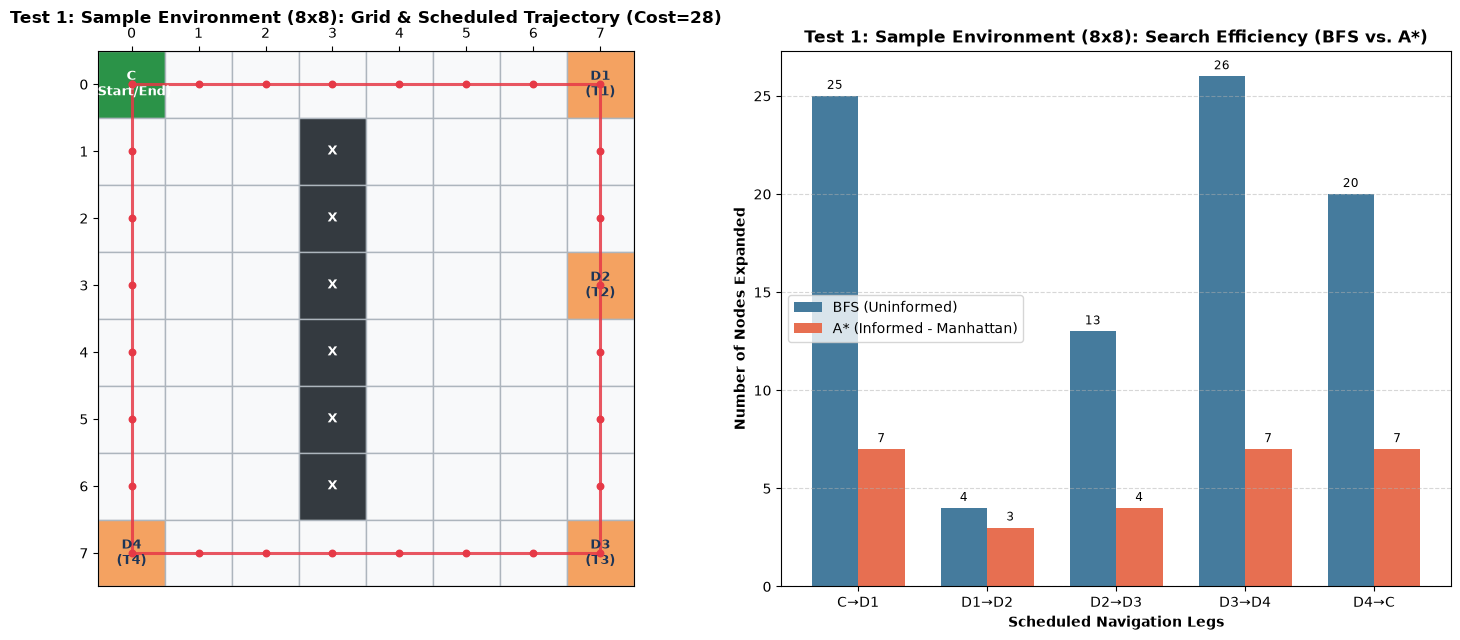

TEST SUITE: Test 2: Custom Environment (10x10)
Files: Environment.txt | Schedule.txt
CSP Status: SUCCESS — Feasible Schedule Generated:
-----------------------------------
Time Slot    | Cleaning Task  
-----------------------------------
T1           | D1             
T2           | D5             
T3           | D2             
T4           | D3             
T5           | D4             
-----------------------------------
Constraint Verification:
  [OK] Precedence (D1 before D3): T1 < T4
  [OK] Precedence (D5 before D2): T2 < T3
  [OK] Precedence (D2 before D4): T3 < T5
  [OK] Precedence (D1 before D4): T1 < T5
  [OK] Latest-Slot (D5 by T2): T2 <= T2
  [OK] Latest-Slot (D1 by T3): T1 <= T3
  [OK] Slot Exclusivity: 5 unique slots for 5 tasks.

--- [Run A: Integrated Execution with A* Search] ---
--- [Run B: Integrated Execution with BFS Search] ---
=== Comparative Analysis: BFS vs. A* (Test 2: Custom Environment (10x10)) ===
Journey Leg  | BFS Cost  | A* Cost  | BFS Nodes  | A* Node

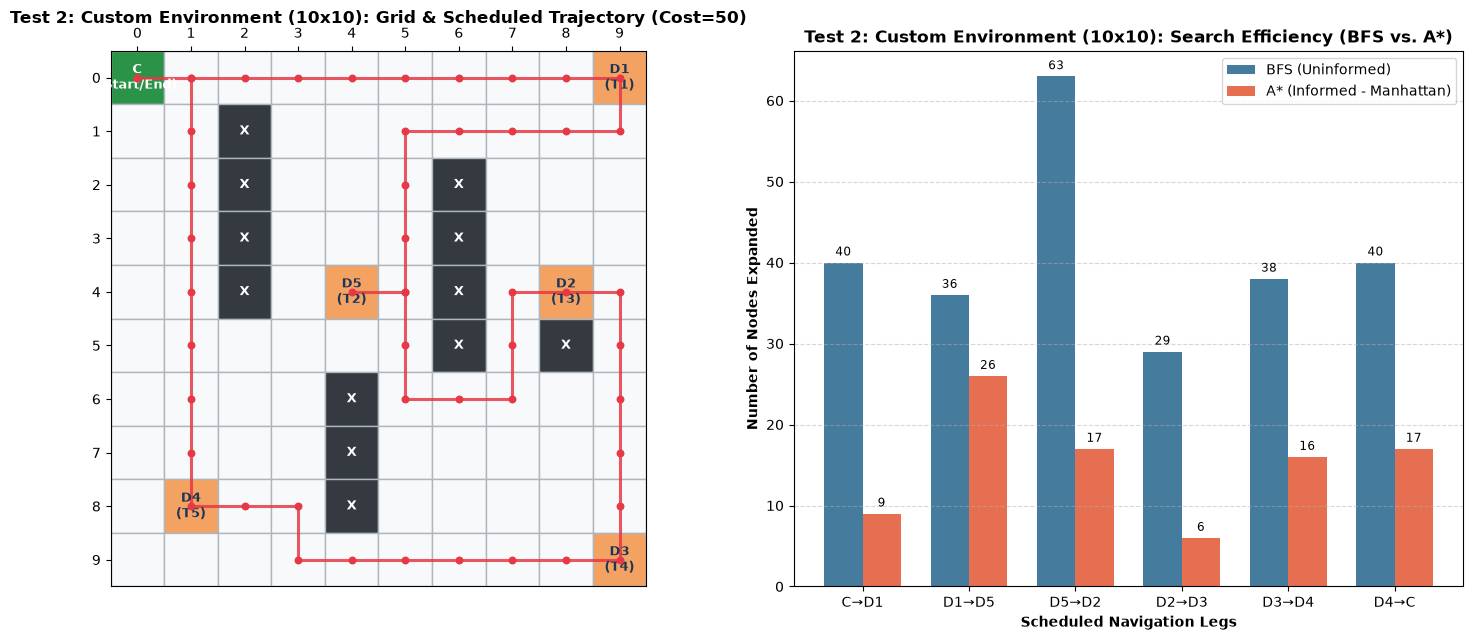

TEST SUITE: Test 3A: Failure Case (Infeasible CSP Schedule)
Files: Environment_Sample.txt | Schedule_Error.txt
CSP Status: FAILED — No feasible cleaning schedule exists for the given constraints.
TEST SUITE: Test 3B: Failure Case (Unreachable Dirty Location)
Files: Environment_Error.txt | Schedule_Sample.txt
CSP Status: SUCCESS — Feasible Schedule Generated:
-----------------------------------
Time Slot    | Cleaning Task  
-----------------------------------
T1           | D1             
T2           | D2             
T3           | D3             
T4           | D4             
-----------------------------------
Constraint Verification:
  [OK] Precedence (D1 before D3): T1 < T3
  [OK] Precedence (D2 before D4): T2 < T4
  [OK] Precedence (D1 before D4): T1 < T4
  [OK] Latest-Slot (D3 by T3): T3 <= T3
  [OK] Latest-Slot (D2 by T3): T2 <= T3
  [OK] Slot Exclusivity: 4 unique slots for 4 tasks.

--- [Run A: Integrated Execution with A* Search] ---
  [FAILURE] Step 2 (T2): No valid path

In [8]:
# ==============================================================================
# SECTION 6: RUNNING ALL THREE MANDATORY VALIDATION TEST SUITES
# ==============================================================================

def run_full_pipeline(env_file, sched_file, label):
    print("=" * 85)
    print(f"TEST SUITE: {label}")
    print(f"Files: {env_file} | {sched_file}")
    print("=" * 85)

    # 1. Load Environment & Schedule
    grid = load_environment(env_file)
    variables, domains, constraints = load_schedule_constraints(sched_file, grid.dirty_locations.keys())

    # 2. Solve CSP Schedule
    assignment = backtracking_search(variables, domains, constraints)
    ordered_schedule = verify_and_display_schedule(assignment, constraints)

    if ordered_schedule is None:
        return

    # 3. Execute Integrated Schedule with BFS and A*
    print("--- [Run A: Integrated Execution with A* Search] ---")
    path_astar, cost_astar, ok_astar = execute_schedule(grid, grid.charging_station, ordered_schedule, algorithm="A*")

    print("--- [Run B: Integrated Execution with BFS Search] ---")
    path_bfs, cost_bfs, ok_bfs = execute_schedule(grid, grid.charging_station, ordered_schedule, algorithm="BFS")

    # 4. Visualize if successful
    if ok_astar:
        visualize_mission_and_comparison(grid, ordered_schedule, title_prefix=label)


# ---> TEST RUN 1: Provided Sample Environment & Schedule
run_full_pipeline("Environment_Sample.txt", "Schedule_Sample.txt", "Test 1: Sample Environment (8x8)")

# ---> TEST RUN 2: Group's Custom Environment & Schedule
run_full_pipeline("Environment.txt", "Schedule.txt", "Test 2: Custom Environment (10x10)")

# ---> TEST RUN 3A: Failure Case - Infeasible Schedule (Schedule_Error.txt)
run_full_pipeline("Environment_Sample.txt", "Schedule_Error.txt", "Test 3A: Failure Case (Infeasible CSP Schedule)")

# ---> TEST RUN 3B: Failure Case - Unreachable Destination (Environment_Error.txt)
run_full_pipeline("Environment_Error.txt", "Schedule_Sample.txt", "Test 3B: Failure Case (Unreachable Dirty Location)")